In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats 
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

In [34]:
df = pd.read_excel('data/gdp_france.xlsx', header=0)

In [35]:
df.columns = df.columns.str.strip()
df['Year'] = pd.to_numeric(df['Year'], errors='coerce').astype('Int64')
df['GDP'] = df['GDP'].astype(str).str.replace(',', '', regex=False)
df['GDP'] = pd.to_numeric(df['GDP'], errors='coerce')

In [36]:

df = df.dropna(subset=['Year'])

In [37]:
df['Year'] = df['Year'].astype(int)
df = df.sort_values('Year').reset_index(drop=True)

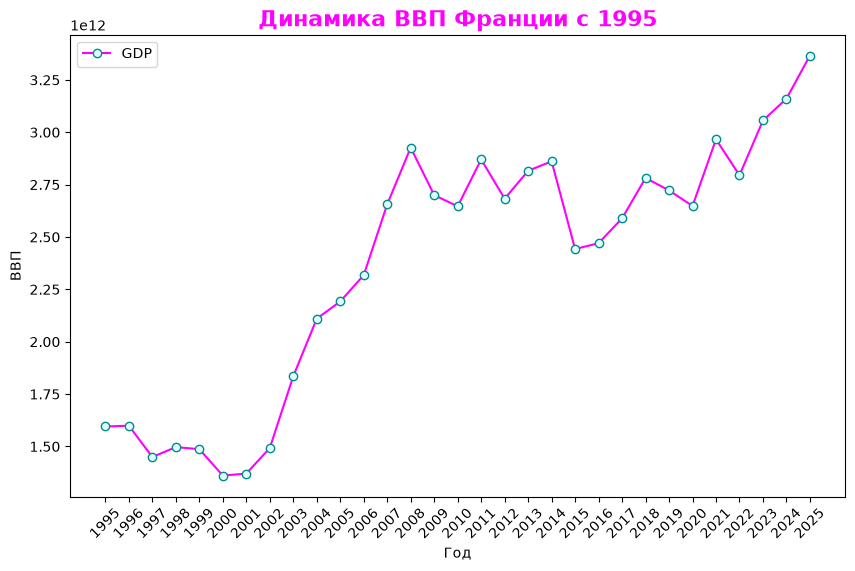

In [38]:

plt.figure(figsize=(10, 6))
plt.plot(df['Year'], df['GDP'], label = 'GDP', marker ='o', color = '#FF00FF', markerfacecolor='#E0FFFF',
         markeredgecolor='#008B8B')
plt.xlabel('Год')
plt.ylabel('ВВП')
plt.xticks(df['Year'])
plt.xticks(rotation = 45)
plt.legend()
plt.title('Динамика ВВП Франции с 1995', fontsize=16, 
          fontweight='bold', 
          color='#FF00FF')

plt.show()

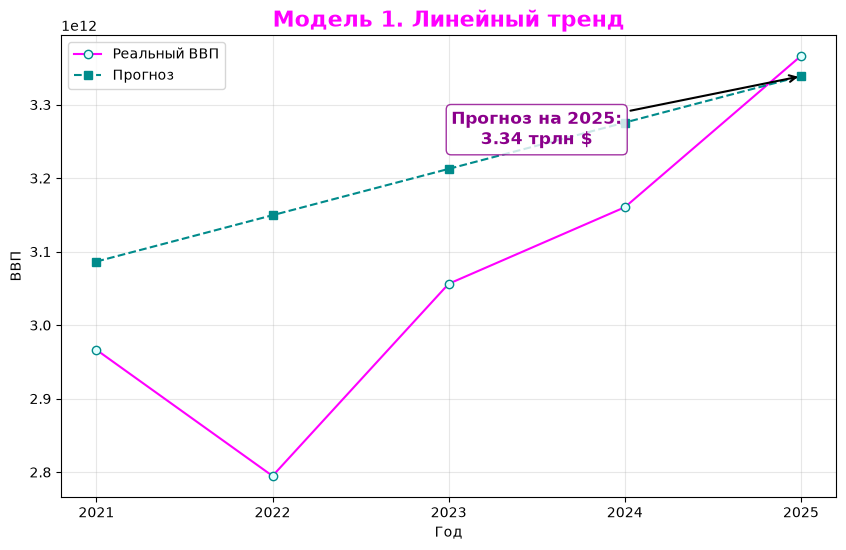

In [39]:
train = df[df['Year'] < 2021]
test = df[df['Year'] >= 2021]
x = train['Year']
y = train['GDP']

slope, intercept = stats.linregress(x, y)[:2]

future_years = test['Year'].values
future_gdp = slope * future_years + intercept

forecasts = {'Линейный тренд': future_gdp}

predict_year = future_years[-1]
gdp_predicted = future_gdp[-1]
text_predicted = f'Прогноз на {predict_year}:\n{gdp_predicted / 1e12:.2f} трлн $'

plt.figure(figsize=(10, 6))


plt.plot(test['Year'], test['GDP'], label = 'Реальный ВВП', marker ='o', color = '#FF00FF', markerfacecolor='#E0FFFF',
         markeredgecolor='#008B8B')
plt.plot(future_years, future_gdp, color = '#008B8B', label= 'Прогноз', marker='s', linestyle='--')


plt.annotate(text_predicted, 
             xy=(predict_year, gdp_predicted), 
             xytext=(predict_year - 1.5, gdp_predicted * 0.97), 
             fontsize=12, 
             fontweight='bold',
             color='#8B008B', 
             ha='center', 
             va='bottom', 
             arrowprops=dict(arrowstyle="->", color='black', lw=1.5), 
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#8B008B", alpha=0.8) 
            )
plt.title('Модель 1. Линейный тренд',fontsize=16, 
          fontweight='bold', 
          color='#FF00FF')
plt.xlabel('Год')
plt.ylabel('ВВП')
plt.xticks(future_years)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Альфа (уровень): 1.000
Бета (тренд): 0.000


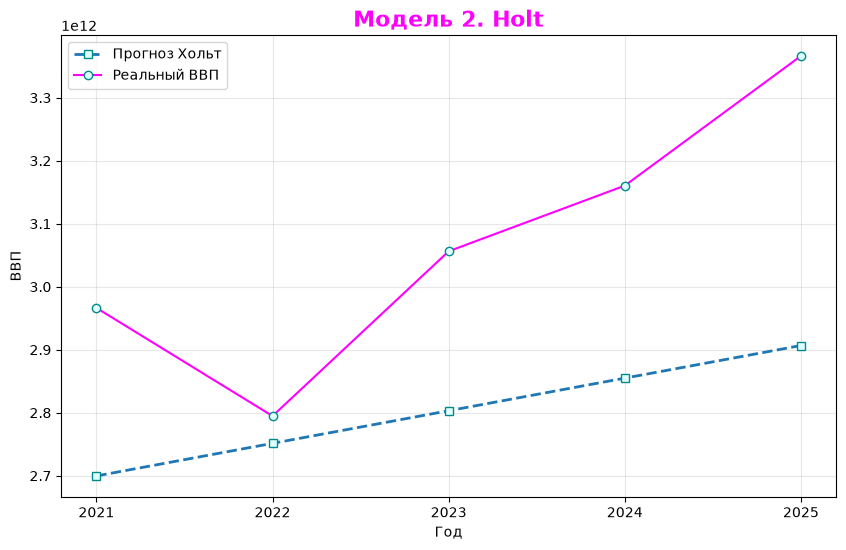

In [40]:
train = df[df['Year'] < 2021].set_index('Year')
test = df[df['Year'] >= 2021].set_index('Year')
train.index = pd.PeriodIndex(train.index, freq='Y')
model = ExponentialSmoothing(train['GDP'],trend='add', seasonal=None).fit()

alpha = model.params['smoothing_level']
beta = model.params['smoothing_trend']

print(f"Альфа (уровень): {alpha:.3f}")
print(f"Бета (тренд): {beta:.3f}")

backtest = model.forecast(len(test))
forecasts['Holt'] = backtest.values
plt.figure(figsize=(10, 6))

plt.plot(test.index, backtest.values, label = 'Прогноз Хольт',  marker='s',                 
         markerfacecolor='#E0FFFF', 
         markeredgecolor='#008B8B',  
         linewidth=2, 
         linestyle='--') 
plt.plot(test.index, test['GDP'].values, label = 'Реальный ВВП', marker ='o', color = '#FF00FF', markerfacecolor='#E0FFFF',
         markeredgecolor='#008B8B')
plt.legend()
plt.xlabel('Год')
plt.ylabel('ВВП')
plt.xticks(test.index)
plt.grid(alpha=0.3)
plt.title('Модель 2. Holt',fontsize=16, 
          fontweight='bold', 
          color='#FF00FF' )
plt.show()

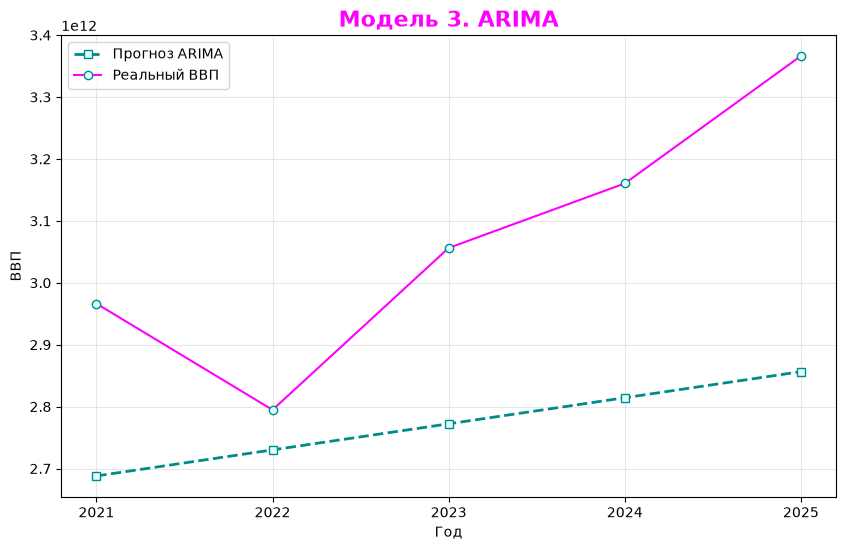

In [41]:
train = df[df['Year'] < 2021].copy()
train = train.set_index('Year')
train.index = pd.PeriodIndex(train.index, freq='Y')
y_train = train['GDP'].dropna().astype(float)

order = (1, 1, 0)


model = ARIMA(y_train, order=order, trend='t')

model_fit = model.fit()
forecast = model_fit.forecast(steps=len(test))
forecasts['ARIMA'] = forecast.values

plt.figure(figsize=(10, 6))

plt.plot(test.index, forecast.values, 
         label='Прогноз ARIMA',  
         marker='s',                 
         color='#008B8B',            
         markerfacecolor='#E0FFFF', 
         markeredgecolor='#008B8B',  
         linewidth=2, 
         linestyle='--') 

plt.plot(test.index, test['GDP'].values, 
         label='Реальный ВВП', 
         marker='o', 
         color='#FF00FF', 
         markerfacecolor='#E0FFFF',
         markeredgecolor='#008B8B')

plt.legend()
plt.xlabel('Год')
plt.ylabel('ВВП')
plt.xticks(test.index)
plt.grid(alpha=0.3)
plt.title('Модель 3. ARIMA', fontsize=16, 
          fontweight='bold', 
          color='#FF00FF')

plt.show()

                MAPE, %
Линейный тренд     5.27
Holt               8.43
ARIMA              9.42

Лучшая модель: Линейный тренд (MAPE = 5.27%)


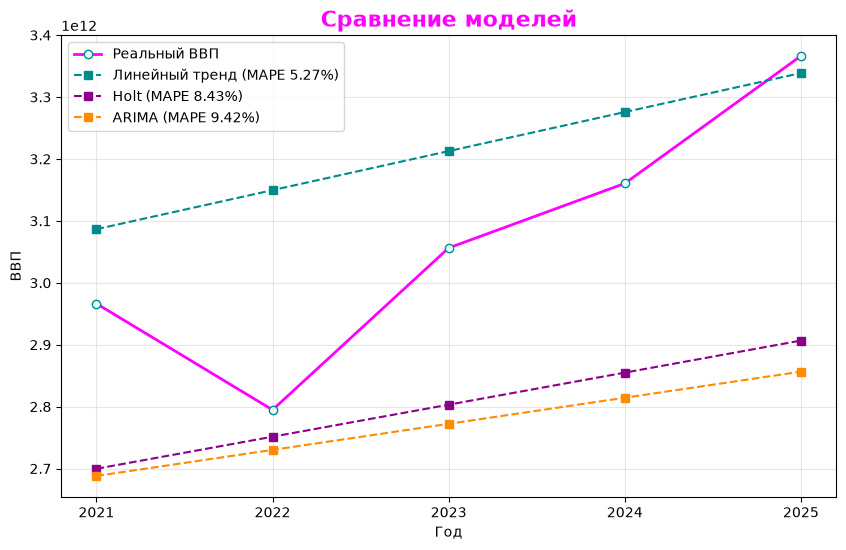

In [42]:
def mape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return np.mean(np.abs((actual - predicted) / actual)) * 100

actual = test['GDP'].values

results = pd.DataFrame({'MAPE, %': {name: mape(actual, pred) for name, pred in forecasts.items()}})
results = results.sort_values('MAPE, %').round(2)
print(results)
print(f"\nЛучшая модель: {results.index[0]} (MAPE = {results.iloc[0, 0]}%)")

plt.figure(figsize=(10, 6))
plt.plot(test.index, actual, label='Реальный ВВП', marker='o', color='#FF00FF',
         markerfacecolor='#E0FFFF', markeredgecolor='#008B8B', linewidth=2)
for (name, pred), color in zip(forecasts.items(), ['#008B8B', '#8B008B', '#FF8C00']):
    plt.plot(test.index, pred, label=f'{name} (MAPE {mape(actual, pred):.2f}%)',
             marker='s', linestyle='--', color=color)
plt.legend()
plt.xlabel('Год')
plt.ylabel('ВВП')
plt.xticks(test.index)
plt.grid(alpha=0.3)
plt.title('Сравнение моделей', fontsize=16, fontweight='bold', color='#FF00FF')
plt.show()